# Exponent- en mantissatruncatie met vaste schaal ×32 / A32 — vijf-epochpilot

Deze proef vergelijkt een **vaste ×32-correctie** met de bestaande ×64-training. E4M3 wordt uit de actuele FP32-gewichten bepaald. E2M3 behoudt de hoogste twee exponentbits van die bron en gebruikt **E8M0-broncode +5**. E2M1 ontstaat vervolgens door twee mantissabits van E2M3 te verwijderen en behoudt dezelfde ×32-schaal. De drie modi delen één E4M3-bron per laag en minibatch.

Activaties blijven **A32**; de gedeelde updatemaster en Adam-momenten blijven **FP32**. De schaalcorrectie wordt niet geleerd. De bronschaal wordt bij volgende minibatches opnieuw uit de actuele gewichten bepaald. Broncode +5 wordt in een breder integer-type berekend; ongeldige E8M0-schalen worden afgewezen zonder clipping of wraparound.

**De twee hoofdgrafieken tonen epoch 5 en het gezamenlijke checkpoint gekozen door de hoogste E4M3-accuracy binnen deze pilot.** Bij een vroege stop wordt de laatste afgeronde epoch duidelijk aangeduid. Epoch 100 wordt in deze proef niet gemeten of voorspeld.

Dit notebook leest uitsluitend opgeslagen JSON/CSV. Het laadt geen dataset, model, checkpoint of optimizer en start geen training.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_scale32_pilot5\\20261024_192400_420212_joint_run')
SAVE_FIGURES = False  # Zet op True om figuren in een nieuwe analysemap te bewaren.


In [2]:
import sys
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:
    class Markdown(str):
        pass
    def display(value):
        print(value)

# Gebruik de helper uit déze run, ook als een eerdere notebook dezelfde modulenaam gebruikte.
helper_path = RUN_DIR.expanduser().resolve() / 'notebook_support.py'
helper_name = '_mx_triple_scale32_pilot5_analysis_helper'
spec = importlib.util.spec_from_file_location(helper_name, helper_path)
if spec is None or spec.loader is None:
    raise FileNotFoundError(f'Analysehelper ontbreekt: {helper_path}')
ns = importlib.util.module_from_spec(spec)
sys.modules[helper_name] = ns
spec.loader.exec_module(ns)
run = ns.load_run(RUN_DIR)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(Markdown('### Meldingen en ontbrekende gegevens'))
display(ns.diagnostics_table(run))


### Opgeslagen SVHN-run — herkomst volgens het runrapport

Runstatus: **PASS** · Analysefouten: **0**. Laatste ingelezen testepoch: **5**.

**Epoch100 niet gemeten als bevestigd eindresultaat.** De laatste beschikbare epoch en het door E4M3 gekozen beste checkpoint blijven zichtbaar. Er wordt geen ontbrekende accuracy voorspeld. De vijf-epochpilot is volgens het runrapport voltooid.

Deze analyse leest uitsluitend opgeslagen JSON/CSV. Zij start geen training en laadt geen model of checkpoint.

,Onderdeel,Opgeslagen configuratie
0,Gewichtsmodi,"MXFP8_E4M3, MXFP6_E2M3, MXFP4_E2M1"
1,Gewichtsroute,E4M3-bron uit actueel G(W) → E2M3 via exponent...
2,Schaal bij lagere modi,E4M3-broncode +5 in E8M0 (×32); E2M1 behoudt d...
3,Schaalgrenzen,Offset in breder integer-type; buiten eindig E...
4,STE,Identity door de volledige codebewerking naar ...
5,Schaal tijdens training,Bron wordt opnieuw bepaald uit actuele gewicht...
6,BatchNorm,Eigen doelbank per modus leert mee tijdens tra...
7,Schaalbeleid,encode current E4M3 source scale floor(log2(am...
8,Activaties / updatemaster,A32 / float32
9,Distillatie,E4M3 hard CE + E2M3 soft CE from detached E4M3...


### Meldingen en ontbrekende gegevens

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## Epoch 5 en beste checkpoint gekozen door E4M3

Het beste checkpoint is het **eerste strikte maximum van de E4M3-testaccuracy binnen de pilot**. Een gelijke score vervangt het eerdere checkpoint niet. E2M3 en E2M1 worden op precies dezelfde epoch gerapporteerd; hun eigen hoogste scores worden niet samengevoegd met een andere E4M3-epoch.

De officiële testset wordt volgens het bestaande protocol voor checkpointselectie gebruikt. De beste score is daardoor geen onafhankelijke testschatting na selectie. Het vaste eindpunt epoch 5 staat er apart naast. Dit is een vroege trainingsproef, geen bewijs welke schaalfactor na honderd epochs het beste is.


,Rol,Controlepunt,Epoch,Gewichtsformaat,Testaccuracy [%],Correct / n,Harde test-CE,Selectiebron,Checkpoint
0,last_epoch,Epoch 5,5,MXFP8_E4M3,92.113553,23.979 / 26.032,0.265791,checkpoint_selection.json,last_checkpoint.pt
1,last_epoch,Epoch 5,5,MXFP6_E2M3,89.762600,23.367 / 26.032,0.335785,checkpoint_selection.json,last_checkpoint.pt
2,last_epoch,Epoch 5,5,MXFP4_E2M1,90.142901,23.466 / 26.032,0.328520,checkpoint_selection.json,last_checkpoint.pt
3,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de p...,5,MXFP8_E4M3,92.113553,23.979 / 26.032,0.265791,checkpoint_selection.json,best_checkpoint.pt
4,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de p...,5,MXFP6_E2M3,89.762600,23.367 / 26.032,0.335785,checkpoint_selection.json,best_checkpoint.pt
5,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de p...,5,MXFP4_E2M1,90.142901,23.466 / 26.032,0.328520,checkpoint_selection.json,best_checkpoint.pt


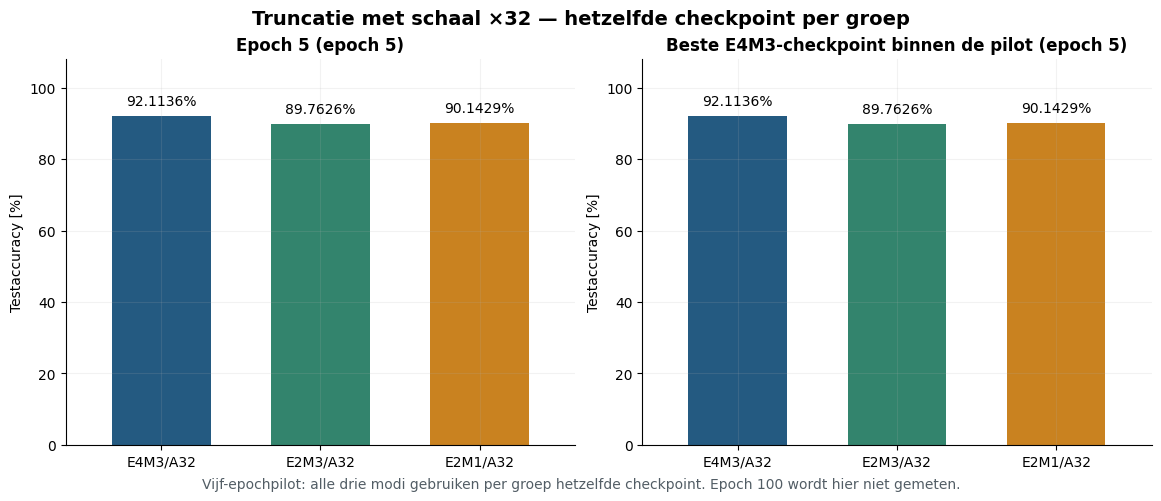

In [3]:
display(ns.checkpoint_table(run).round({'Testaccuracy [%]': 6, 'Harde test-CE': 8}))
figures['checkpoint_accuracy'] = ns.plot_checkpoint_accuracy(run)
display(figures['checkpoint_accuracy'])
plt.close(figures['checkpoint_accuracy'])


## Vergelijking met vaste schaal ×64 op dezelfde vroege epochs

De meegeleverde ×64-referentie bevat de eerder uitgevoerde honderd-epochtraining, maar de onderstaande vergelijking gebruikt **uitsluitend epochs 1 tot en met 5**. De curves stoppen bij de laatste beschikbare ×32-epoch. De epoch-5-vergelijking verschijnt pas wanneer de ×32-pilot epoch 5 heeft bereikt.

Voor de beste-checkpointvergelijking wordt de hoogste E4M3-accuracy per training opnieuw bepaald **binnen de gezamenlijke vroege epochrange**. Alle drie modi horen telkens bij dat ene checkpoint. De globale beste epoch van de honderd-epochreferentie wordt niet gebruikt. De initialisatie, instellingen en referentiebestanden worden gecontroleerd voordat een vergelijking verschijnt.


### Vaste schaal ×32 tegenover ×64: uitsluitend de eerste vijf epochs

De ×64-cijfers komen uit de eerste vijf epochs van de bestaande honderd-epochtraining. De globale beste epoch en epoch 100 van die run worden hier niet gebruikt. Voor ieder model worden alle drie modi op één gezamenlijk checkpoint getoond; het beste checkpoint wordt uitsluitend gekozen op E4M3 binnen de vergeleken vroege epochs. 

**Vergelijking beschikbaar voor epochs 1–5.** Dezelfde seed, oorspronkelijke modelstaat en trainingsinstellingen zijn bevestigd, afgezien van de vaste schaalcorrectie en de pilotduur. Dit garandeert geen bitexacte CUDA-herhaalbaarheid. Vijf epochs bepalen niet welke factor na honderd epochs het beste presteert.

,Controlepunt,Gewichtsformaat,Epoch ×32,Epoch ×64,×32 accuracy [%],×64 accuracy [%],Verschil ×32 − ×64 [pp],×32 harde CE,×64 harde CE
0,Epoch 5,MXFP8_E4M3,5,5,92.113553,93.008605,-0.895052,0.265791,0.243082
1,Epoch 5,MXFP6_E2M3,5,5,89.762600,91.299170,-1.536570,0.335785,0.298985
2,Epoch 5,MXFP4_E2M1,5,5,90.142901,90.891979,-0.749078,0.328520,0.310513
3,Beste E4M3 binnen epochs 1–5,MXFP8_E4M3,5,5,92.113553,93.008605,-0.895052,0.265791,0.243082
4,Beste E4M3 binnen epochs 1–5,MXFP6_E2M3,5,5,89.762600,91.299170,-1.536570,0.335785,0.298985
5,Beste E4M3 binnen epochs 1–5,MXFP4_E2M1,5,5,90.142901,90.891979,-0.749078,0.328520,0.310513


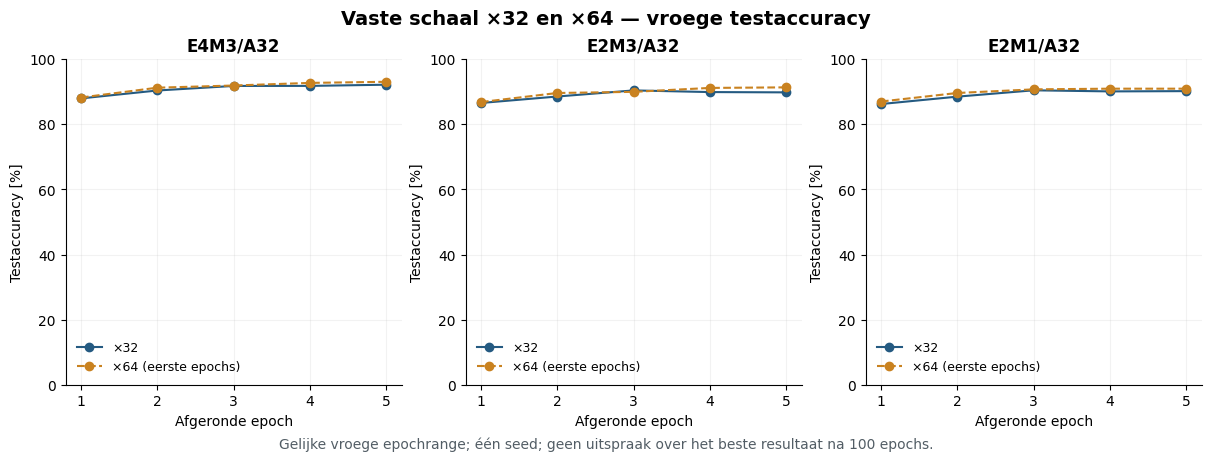

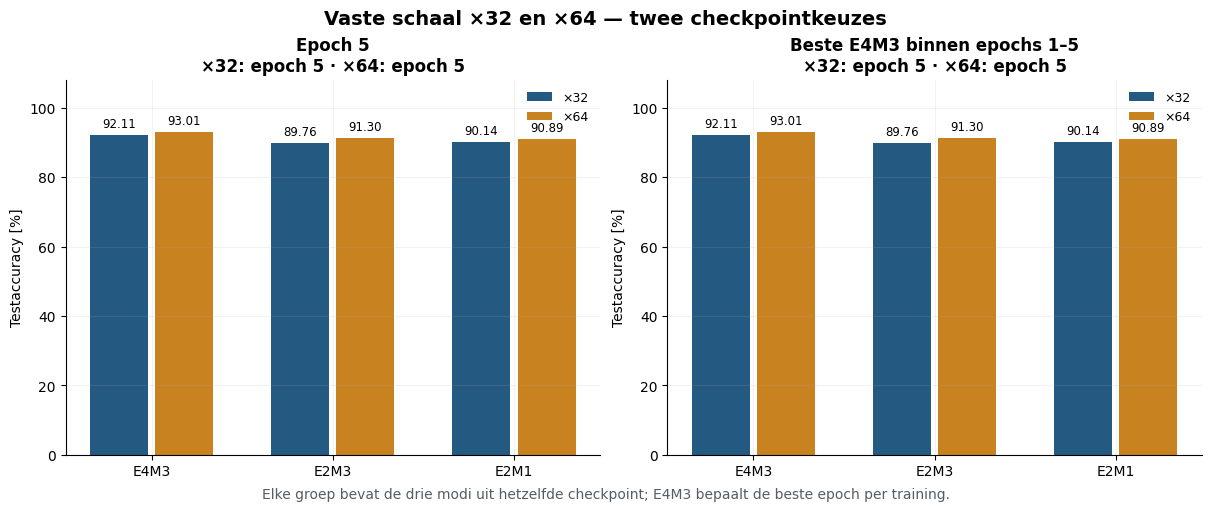

In [4]:
reference = ns.load_scale64_reference(run)
display(Markdown(ns.comparison_markdown(run, reference)))
display(ns.comparison_table(run, reference).round(6))
figures['scale_comparison_curves'] = ns.plot_scale_comparison_curves(run, reference)
display(figures['scale_comparison_curves'])
plt.close(figures['scale_comparison_curves'])
figures['scale_comparison_checkpoints'] = ns.plot_scale_comparison_checkpoints(run, reference)
display(figures['scale_comparison_checkpoints'])
plt.close(figures['scale_comparison_checkpoints'])


## Train- en testaccuracy per modus

De drie modi worden gezamenlijk vanaf een nieuwe initialisatie getraind. Trainaccuracy wordt tijdens de updates verzameld. Testaccuracy wordt na iedere epoch gemeten met dezelfde ×32-truncatieroute, bevroren evaluatiestaat en volledige testset. De drie modusgebonden BatchNorm-banken leren tijdens de training normaal mee.


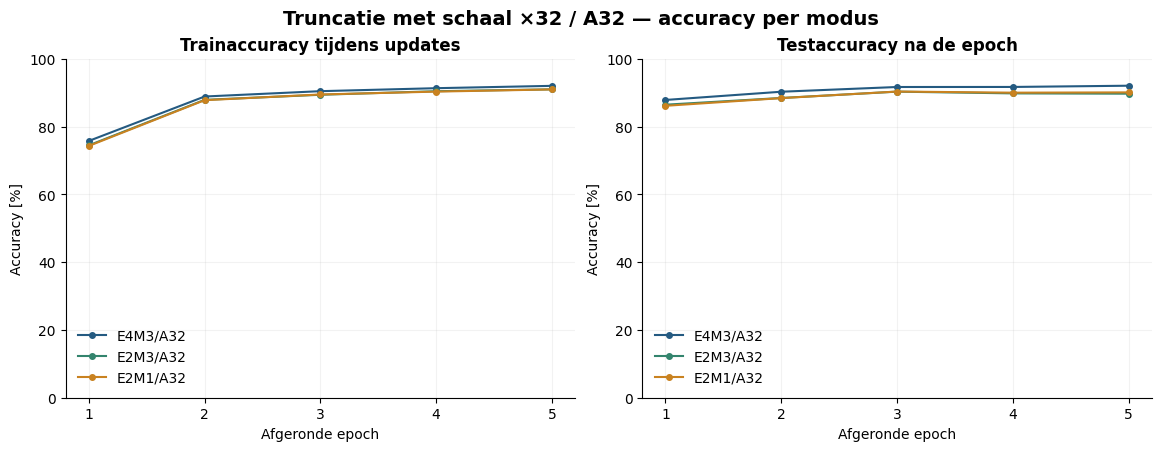

In [5]:
figures['accuracy_curves'] = ns.plot_learning(run)
display(figures['accuracy_curves'])
plt.close(figures['accuracy_curves'])


## Losses: trainingsdoelen onderscheiden van harde test-CE

De trainpass van E4M3 gebruikt harde CE van labels. Daarna leert E2M3 met soft-target CE van de **detached E4M3-softmax**; E2M1 leert met soft-target CE van de **detached E2M3-softmax**. Dit is recursieve distillatie met T=1. De drie gradients worden gesommeerd zonder deling door drie, waarna één Adam-update volgt; er is geen extra FP32-teacherforward.

De drie trainobjectieven staan in afzonderlijke panelen omdat hun targets verschillen. Soft CE is geen harde label-CE en wordt hier ook niet als KL-divergentie aangeduid. **Testloss is voor alle drie modi harde CE van dezelfde labels** en staat daarom samen in één vergelijkbaar paneel.


,epoch,phase,weight_format,objective_type,objective_loss
0,1,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.941892
1,1,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.874722
2,1,train,MXFP8_E4M3,hard_cross_entropy,0.737323
3,1,test,MXFP4_E2M1,hard_cross_entropy,0.446853
4,1,test,MXFP6_E2M3,hard_cross_entropy,0.436677
5,1,test,MXFP8_E4M3,hard_cross_entropy,0.399066
6,2,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.502571
7,2,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.450174
8,2,train,MXFP8_E4M3,hard_cross_entropy,0.363536
9,2,test,MXFP4_E2M1,hard_cross_entropy,0.390267


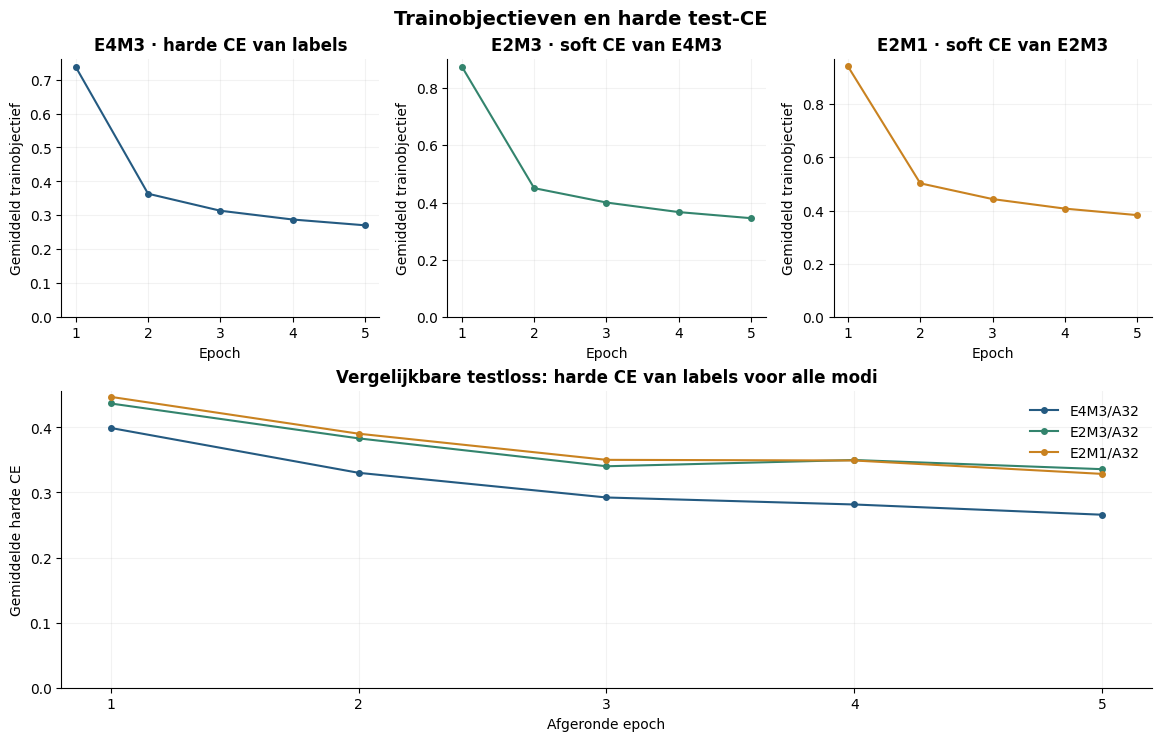

In [6]:
if not run.metrics.empty:
    objective_columns = [key for key in ('epoch', 'phase', 'weight_format', 'objective_type', 'objective_loss') if key in run.metrics]
    display(run.metrics[objective_columns].round({'objective_loss': 8}))
figures['objective_losses'] = ns.plot_objectives(run)
display(figures['objective_losses'])
plt.close(figures['objective_losses'])


## Blijft het netwerk verschillende cijfers voorspellen?

De eerdere post-hocproeven lieten bij sommige routes sterk vertekende of constante voorspellingen zien. Daarom wordt hier per testepoch en per modus bijgehouden hoe de voorspellingen over de tien cijfers verdeeld zijn. Een constante voorspelling is direct zichtbaar als **één gebruikte klasse en 100% concentratie**. De tabel toont ook hoe vaak het dominante cijfer werkelijk in de testset voorkomt.

Dit zijn geaggregeerde tellingen; deze notebook doet geen nieuwe inferentie en leidt er geen per-beeldvergelijking uit af.


,Rol,Epoch,Gewichtsformaat,Voorspelde klassen,Meest voorspelde cijfer,Aandeel dominant cijfer [%],Aandeel dat cijfer in labels [%],Testaccuracy [%],Constante voorspelling,Testbeelden,Tellingen voorspeld cijfer 0..9,Tellingen echt cijfer 0..9
0,last_epoch,5,MXFP8_E4M3,10,1,19.998463,19.587431,92.113553,False,26032,"[1867, 5206, 4123, 3151, 2405, 2285, 1939, 198...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
1,last_epoch,5,MXFP6_E2M3,10,1,20.624616,19.587431,89.762600,False,26032,"[2005, 5369, 3936, 3488, 2249, 2228, 1822, 181...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
2,last_epoch,5,MXFP4_E2M1,10,1,20.309619,19.587431,90.142901,False,26032,"[1964, 5287, 3986, 3478, 2281, 2172, 1855, 184...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
3,best_E4M3_test,5,MXFP8_E4M3,10,1,19.998463,19.587431,92.113553,False,26032,"[1867, 5206, 4123, 3151, 2405, 2285, 1939, 198...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
4,best_E4M3_test,5,MXFP6_E2M3,10,1,20.624616,19.587431,89.762600,False,26032,"[2005, 5369, 3936, 3488, 2249, 2228, 1822, 181...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
5,best_E4M3_test,5,MXFP4_E2M1,10,1,20.309619,19.587431,90.142901,False,26032,"[1964, 5287, 3986, 3478, 2281, 2172, 1855, 184...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."


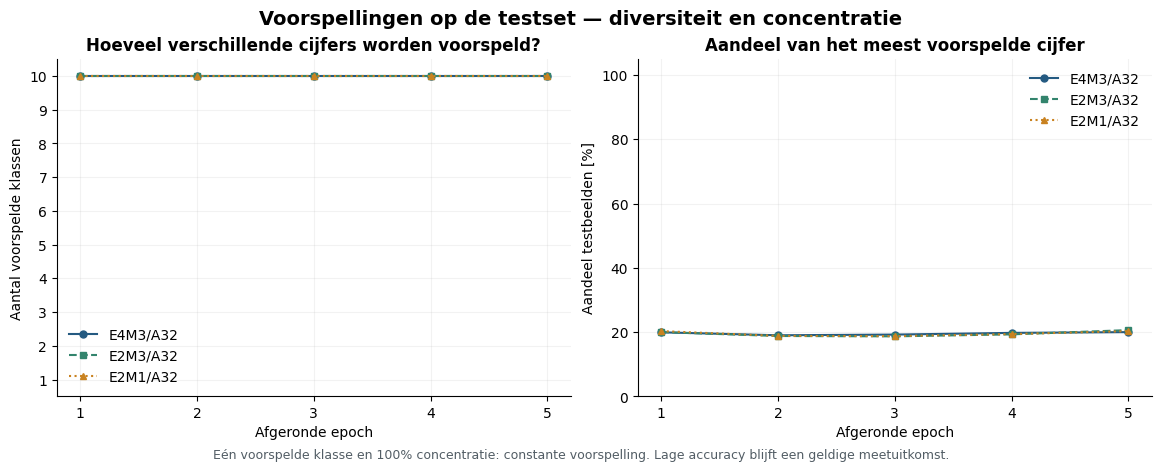

In [7]:
display(ns.prediction_table(run, selected_only=True))
figures['prediction_diversity'] = ns.plot_prediction_diversity(run)
display(figures['prediction_diversity'])
plt.close(figures['prediction_diversity'])


## Gemeten trainingsduur en voorlopige projectie naar honderd epochs

**Gemeten som over 5 afgeronde epochs: 315.59 s (5.26 minuten).** Warme epochs volgens het tijdsrapport: **[2, 3, 4, 5]**; mediaan: **63.2 s**. De afzonderlijke projectie geldt voor een **nieuwe volledige run van honderd epochs vanaf initialisatie**. Zij is geen gemeten eindtijd en geen resterende hervattijd. Het waargenomen minimum/maximum van de warme epochs levert een scenario-bereik, geen betrouwbaarheidsinterval. Vijf epochs meten de LR-overgangen op 50/75/90 en langdurige thermische omstandigheden nog niet. Download, installatie, data-inladen en eindrapportage zijn niet inbegrepen. **Geen accuracy voor epoch100 wordt voorspeld.**

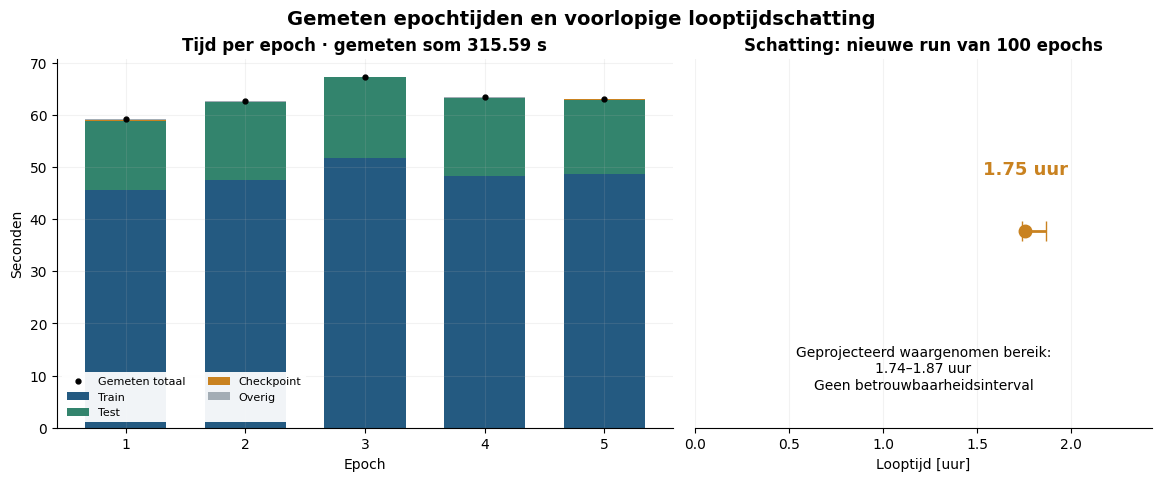

In [8]:
display(Markdown('## Gemeten trainingsduur en voorlopige projectie naar honderd epochs'))
display(Markdown(ns.timing_markdown(run)))
figures['timing'] = ns.plot_timing(run)
display(figures['timing'])
plt.close(figures['timing'])


## GPU-geheugen

De opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.

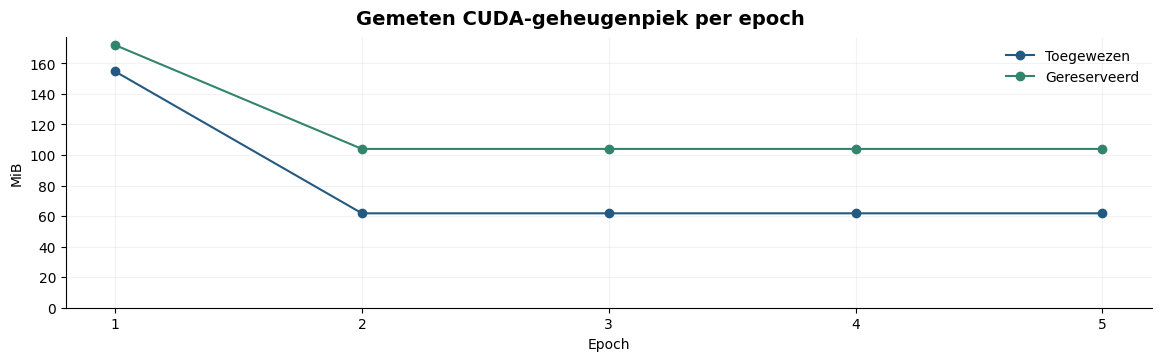

In [9]:
display(Markdown('## GPU-geheugen\n\nDe opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.'))
figures['gpu_memory'] = ns.plot_memory(run)
display(figures['gpu_memory'])
plt.close(figures['gpu_memory'])


In [10]:
display(Markdown('## Opgeslagen technische controles\n\nDeze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.'))
display(ns.audit_table(run))
display(Markdown('### Gewichtsupdates\n\nDe mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.'))
display(ns.weight_update_table(run))
display(Markdown('### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint'))
display(ns.export_table(run))


## Opgeslagen technische controles

Deze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.

,Opgeslagen controle,Resultaat volgens rapport
0,Gradientcontrole vóór iedere gezamenlijke update,True
1,FP32-masters en Adam-momenten geverifieerd,True
2,Lagere schaalcodes exact E4-bron +5,True
3,E2M1 behoudt de E2M3-schaalbytes,True
4,Eén E4-bron per laag per minibatch,True
5,Broncache leeg vóór iedere optimizerupdate,True
6,BN-tellers van alle opgeslagen epochs correct,True
7,Geen optimizerupdates tijdens evaluatie,True
8,Bronbestanden onveranderd,True
9,Ruwe datasetbestanden onveranderd,True


### Gewichtsupdates

De mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.

,epoch,weight_format,layer,master_changed_values,master_update_l2,master_dtype,changed_element_codes_including_padding,changed_scale_codes
0,1,MXFP4_E2M1,layers.3,1728,1.523332,torch.float32,1104,0
1,1,MXFP6_E2M3,layers.3,1728,1.523332,torch.float32,1546,0
2,1,MXFP8_E4M3,layers.3,1728,1.523332,torch.float32,1620,0
3,1,MXFP4_E2M1,layers.6,2304,1.856157,torch.float32,1426,0
4,1,MXFP6_E2M3,layers.6,2304,1.856157,torch.float32,2072,0
...,...,...,...,...,...,...,...,...
85,5,MXFP6_E2M3,layers.16,9216,1.457542,torch.float32,7980,0
86,5,MXFP8_E4M3,layers.16,9216,1.457542,torch.float32,8179,0
87,5,MXFP4_E2M1,layers.20,101435,5.311011,torch.float32,54358,440
88,5,MXFP6_E2M3,layers.20,101435,5.311011,torch.float32,85833,440


### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint

,Rol,Epoch,Gewichtsformaat,Bestand,Bestandsbytes,Gewichten exact gereconstrueerd,Zes FP32-masters afwezig,Volledige exporttest opnieuw,Truncatie,Bron of afleiding,E4-bronschaalbytes behouden,Schaalexponentoffset tegenover E4,Schaalfactor tegenover E4,Masters gelezen voor afleiding,Opgeslagen en herladen,Bronbestand-SHA256
0,best_E4M3_test,5,MXFP8_E4M3,mx_source_MXFP8_E4M3_best.pt,196773,True,True,False,False,E4M3-bron,True,0,1,False,True,5d4d8ba0a8c15e2edc35cdb5e7c12d908d4f563246f326...
1,best_E4M3_test,5,MXFP6_E2M3,mx_derived_MXFP6_E2M3_best.pt,164773,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,5,32,False,True,5d4d8ba0a8c15e2edc35cdb5e7c12d908d4f563246f326...
2,best_E4M3_test,5,MXFP4_E2M1,mx_derived_MXFP4_E2M1_best.pt,132133,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,5,32,False,True,5d4d8ba0a8c15e2edc35cdb5e7c12d908d4f563246f326...
3,last_epoch,5,MXFP8_E4M3,mx_source_MXFP8_E4M3_last.pt,196773,True,True,False,False,E4M3-bron,True,0,1,False,True,5d4d8ba0a8c15e2edc35cdb5e7c12d908d4f563246f326...
4,last_epoch,5,MXFP6_E2M3,mx_derived_MXFP6_E2M3_last.pt,164773,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,5,32,False,True,5d4d8ba0a8c15e2edc35cdb5e7c12d908d4f563246f326...
5,last_epoch,5,MXFP4_E2M1,mx_derived_MXFP4_E2M1_last.pt,132133,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,False,5,32,False,True,5d4d8ba0a8c15e2edc35cdb5e7c12d908d4f563246f326...


## Interpretatie en grenzen

De gerichte wijziging tegenover ×64 is **offset +5 in plaats van +6** voor beide lagere precisies. De mantissatruncatie behoudt de E2M3-schaal. Er is geen directe lagere kwantisatie, geen geleerde schaal en geen extra FP32-teacherpass. De identity-STE geldt voor de volledige codebewerking naar G(W), zonder factor32 in de backward; de oorspronkelijke G(W)-afgeleide blijft behouden.

Een lage accuracy of constante voorspelling blijft een onderzoeksuitkomst wanneer de technische controles slagen. Een dalende soft-target trainingsloss bewijst op zichzelf geen betere classificatie. Bekijk daarom testaccuracy, harde test-CE en voorspellingstellingen samen.

De vergelijking met ×64 gebruikt een bestaande afzonderlijke training met dezelfde oorspronkelijke initialisatie en instellingen, afgezien van de vaste correctie. De originele cuDNN-backend is niet bitexact gegarandeerd. Deze proef heeft één seed en vijf epochs; een klein verschil bewijst geen algemene superioriteit of optimale schaalfactor. De beste E4M3-score selecteert op de officiële testset en is geen onafhankelijke testschatting.

De tijdprojectie voor honderd epochs is uitsluitend een looptijdschatting. Er wordt geen accuracy voor epoch 100 berekend. De geheugenfiguur betreft de CUDA-allocator van de FP32-emulator en meet geen native MX-kernel, hardwareversnelling of energiewinst.


In [11]:
if SAVE_FIGURES:
    analysis_dir = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', analysis_dir)
else:
    print('Alleen analyse in het notebook; geen figuren naar schijf geschreven.')
print('Ingelezen resultaatmap:', run.path)
display(pd.DataFrame({'Ingelezen bestand': [str(path.relative_to(run.path)) if path.is_relative_to(run.path) else str(path) for path in run.input_files]}))


Alleen analyse in het notebook; geen figuren naar schijf geschreven.
Ingelezen resultaatmap: C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_scale32_pilot5\20261024_192400_420212_joint_run


,Ingelezen bestand
0,run_report.json
1,history.json
2,training_summary.json
3,checkpoint_selection.json
4,timing_estimate.json
5,epoch_metrics.csv
6,selected_metrics.csv
7,epoch_times.csv
8,weight_updates.csv
9,scale64_reference\REFERENCE.json
